# Energy poverty and dynamic tariffs

One connected analysis of the SERL data (2020–2023) with real 2024 Octopus prices:

1. **Natural groupings (HDBSCAN):** which household types use electricity alike, and where the groups linked to energy poverty fall.
2. **Energy-poverty signals:** under-consumption, the 2022 cut-back, heating strain, and access to solar and electric heating, checked for changes in the sample.
3. **SARIMA forecasts** of 2024 use for vulnerable and comparison groups.
4. **2024 tariffs:** Agile vs flat bills from those forecasts, standing charges, and the *flexibility gap* and *access gap* scenarios.

**What the data can and cannot show.** SERL Study 8963 contains **group summaries, not individual households**. Each row describes one group (e.g. "IMD quintile 1, electric heating, no PV"), one characteristic at a time crossed with heating fuel and PV. Everything below is about *groups*; no individual household can be identified as fuel-poor, and two characteristics (e.g. deprivation *and* tenure) cannot be combined.

**Energy-poverty proxies used** (there is no income or fuel-poverty flag in the data):
- *Vulnerable:* IMD quintiles 1–2 (most deprived areas), social and private renting, EPC bands E and F–G, electric storage radiators.
- *Comparators:* IMD quintiles 4–5, owner-occupiers, EPC bands A–B and C.

**Inputs:** SERL files via `serl_utils.py`; Octopus Agile (December 2023 v1, which covers all of 2024) and Flexible Octopus prices for 2024 via `tariff_utils.py`, GSP region C. **Outputs:** `outputs/energy_poverty/*.csv`.


In [1]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import hdbscan
import umap
from scipy.stats import fisher_exact, mannwhitneyu
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import adjusted_rand_score
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tools.sm_exceptions import ConvergenceWarning
import serl_utils as su
import tariff_utils as tu

for w in (UserWarning, FutureWarning, ConvergenceWarning):
    warnings.filterwarnings("ignore", category=w)
OUT = Path("outputs/energy_poverty"); OUT.mkdir(parents=True, exist_ok=True)
hh = su.load_half_hourly([2023])
monthly = su.load_monthly(su.CLEAN_CSV)
yearly = su.load_yearly()
ELEC, GAS = "Electricity imports", "Gas"

VULNERABLE = {("IMD_quintile", "1"), ("IMD_quintile", "2"), ("tenure", "Social rent"), ("tenure", "Private rent"),
              ("currentEnergyRating", "E"), ("currentEnergyRating", "F and G"),
              ("central_heating_type", "Electric storage radiators")}
COMPARATOR = {("IMD_quintile", "4"), ("IMD_quintile", "5"), ("tenure", "Own outright or mortgage"),
              ("currentEnergyRating", "A and B"), ("currentEnergyRating", "C")}

def seg(s, v):
    return {"segment": s, "segment_value": v}

# named groups used in parts 2–4 (all heating fuels and PV statuses unless stated)
FOCUS = {"All households": {},
         **{f"IMD {q}" + (" (most deprived)" if q == "1" else " (least deprived)" if q == "5" else ""): seg("IMD_quintile", q)
            for q in "12345"},
         "Social rent": seg("tenure", "Social rent"), "Private rent": seg("tenure", "Private rent"),
         "Owner-occupied": seg("tenure", "Own outright or mortgage"),
         "EPC A–B": seg("currentEnergyRating", "A and B"), "EPC C": seg("currentEnergyRating", "C"),
         "EPC D": seg("currentEnergyRating", "D"), "EPC E": seg("currentEnergyRating", "E"),
         "EPC F–G": seg("currentEnergyRating", "F and G"),
         "Gas heating": {"fuel": "Gas"}, "Electric heating": {"fuel": "Electric"}}
print(f"{len(FOCUS)} named groups; half-hourly rows {len(hh):,}, monthly rows {len(monthly):,}")

16 named groups; half-hourly rows 490,320, monthly rows 490,320


## 1. Natural groupings among household types (HDBSCAN)

**Points:** every SERL *group-cell* (one level of one characteristic × heating fuel × PV, plus the whole sample by fuel × PV) with a complete 2023 half-hourly profile, complete 2023 months, 2021 and 2023 annual values, and **at least 50 households in every file used** (smaller cells are too noisy). This also drops most solar-PV cells: from 2022 SERL's daily and monthly statistics include only 20–40 PV homes, against 680 in 2021.

**Features (electricity imports):** level of use (log kWh/day), share of the day's use at night (00–06), morning (06–09), daytime (09–16) and evening peak (16–19), winter/summer ratio, and change 2021→2023.

**HDBSCAN** finds dense groups and leaves cells that fit none as *noise*. Its two settings are chosen by the density-based validity score (DBCV) over a grid. The same households can appear in several cells (e.g. "IMD 1" and "social rent"), so the cells are not independent and the tests below are indicative.


In [2]:
KEYS = ["segmentation_variable_3", "segment_3_value", "primary_space_heating_fuel", "has_PV"]

def cells(df, unit):
    d = df[df["quantity"].eq(ELEC) & df["unit"].eq(unit) & df["weekday_weekend"].eq("both")
           & df["segmentation_variable_3"].ne("temperature_band")].copy()
    d = d[~d["segment_3_value"].astype(str).eq("All")]
    d["segmentation_variable_3"] = d["segmentation_variable_3"].fillna("whole sample")
    d["segment_3_value"] = d["segment_3_value"].astype(str).replace("nan", "all")
    return d

h = cells(hh, "Wh"); mm = cells(monthly[monthly["date"].dt.year.eq(2023)], "kWh/day"); yy = cells(yearly, "kWh/day")
prof = h.pivot_table(index=KEYS, columns="half_hour", values="mean")
# households behind each cell: smallest count across every file used (half-hourly 2023, monthly 2023, yearly 2021 and 2023)
n_hh = pd.concat([h.groupby(KEYS)["n_rounded"].min(), mm.groupby(KEYS)["n_rounded"].min(),
                  yy[yy["year"].isin([2021, 2023])].groupby(KEYS)["n_rounded"].min()], axis=1).min(axis=1)
mon = mm.pivot_table(index=KEYS, columns=mm["date"].dt.month, values="mean")
ann = yy.pivot_table(index=KEYS, columns="year", values="mean")
idx = prof.dropna().index.intersection(mon.dropna().index).intersection(ann[[2021, 2023]].dropna().index)
print(f"{len(prof)} cells; complete for all features: {len(idx)}; with >= 50 households in every file: {(n_hh.reindex(idx) >= 50).sum()}")
idx = idx[n_hh.reindex(idx) >= 50]

P = prof.loc[idx]
share = P.div(P.sum(axis=1), axis=0)
window = lambda a, b: share.loc[:, a:b - 1].sum(axis=1)     # half-hour slots a..b-1
F = pd.DataFrame({
    "log kWh/day": np.log(P.sum(axis=1) / 1000),
    "night 00–06": window(0, 12), "morning 06–09": window(12, 18),
    "day 09–16": window(18, 32), "evening 16–19": window(32, 38),
    "winter/summer": mon.loc[idx, [1, 2, 12]].mean(axis=1) / mon.loc[idx, [6, 7, 8]].mean(axis=1),
    "change 2021→23 %": 100 * (ann.loc[idx, 2023] / ann.loc[idx, 2021] - 1),
}, index=idx)
role = pd.Series(["vulnerable" if (s, v) in VULNERABLE else "comparator" if (s, v) in COMPARATOR else "other"
                  for s, v in zip(idx.get_level_values(0), idx.get_level_values(1))], index=idx, name="role")
stratum = idx.get_level_values(2) + " heating · PV " + idx.get_level_values(3)
print(role.value_counts().to_string())
print(F.describe().loc[["mean", "std", "min", "max"]].round(3).to_string())

504 cells; complete for all features: 393; with >= 50 households in every file: 337
role
other         273
vulnerable     38
comparator     26
      log kWh/day  night 00–06  morning 06–09  day 09–16  evening 16–19  winter/summer  change 2021→23 %
mean        2.223        0.203          0.108      0.285          0.158          1.727           -16.449
std         0.300        0.060          0.011      0.031          0.016          0.579             4.377
min         1.458        0.142          0.084      0.169          0.089          1.089           -32.998
max         3.084        0.468          0.145      0.328          0.179          3.253            -1.958


In [3]:
Z = StandardScaler().fit_transform(F)
grid = []
for mcs in (5, 8, 10, 15):
    for ms in (3, 5, 10):
        c = hdbscan.HDBSCAN(min_cluster_size=mcs, min_samples=ms, gen_min_span_tree=True).fit(Z)
        grid.append({"min_cluster_size": mcs, "min_samples": ms, "groups": c.labels_.max() + 1,
                     "noise %": 100 * (c.labels_ == -1).mean(), "DBCV": c.relative_validity_, "labels": c.labels_})
grid = pd.DataFrame(grid)
best = grid.loc[grid["DBCV"].idxmax()]
print(grid.drop(columns="labels").round(3).to_string(index=False))
print(f"\nChosen: min_cluster_size={best.min_cluster_size}, min_samples={best.min_samples} "
      f"({best.groups} groups, {best['noise %']:.0f}% noise, DBCV {best.DBCV:.3f})")
labels = pd.Series(best["labels"], index=idx, name="group")
near = grid[(grid["groups"] >= 2) & (grid.index != best.name)].nlargest(3, "DBCV")
for _, r in near.iterrows():
    print(f"  agreement with next-best setting ({r.min_cluster_size}, {r.min_samples}): ARI = {adjusted_rand_score(labels, r['labels']):.2f}")

# name each group from its average features (relative to all cells) and its heating-fuel mix
mu, sd = F.mean(), F.std()
fuel = pd.Series(idx.get_level_values(2), index=idx)
def describe(g):
    m = F[labels == g].mean()
    z = (m - mu) / sd
    lvl = "high use" if z["log kWh/day"] > 0.5 else "low use" if z["log kWh/day"] < -0.5 else "mid use"
    tags = [lvl]
    if z["night 00–06"] > 1: tags.append("night-heavy")
    if z["evening 16–19"] > 0.5: tags.append("evening-peaky")
    if z["day 09–16"] > 0.5: tags.append("daytime")
    if z["winter/summer"] > 1: tags.append("strongly seasonal")
    main_fuel = fuel[labels == g].value_counts(normalize=True)
    lead = main_fuel.index[0] + " heating" if main_fuel.iloc[0] >= 0.6 and main_fuel.index[0] != "All" else "mixed heating"
    return f"G{g}: {lead}, " + ", ".join(tags)
names = {g: describe(g) for g in sorted(labels.unique()) if g >= 0}
names[-1] = "Noise (fits no group)"
group_name = labels.map(names)

summary = F.groupby(group_name).mean()
summary.insert(0, "cells", group_name.value_counts())
summary["kWh/day"] = np.exp(summary.pop("log kWh/day"))
print("\nGroups (feature means)")
print(summary.round(3).to_string())
print("\nRole of cells in each group")
print(pd.crosstab(group_name, role).to_string())

noise = labels.eq(-1)
v = role.eq("vulnerable")
odds, p = fisher_exact([[int((v & noise).sum()), int((v & ~noise).sum())],
                        [int((~v & noise).sum()), int((~v & ~noise).sum())]])
print(f"\nVulnerable cells classed as noise: {100 * (v & noise).sum() / v.sum():.0f}% vs "
      f"{100 * (~v & noise).sum() / (~v).sum():.0f}% of other cells (Fisher p = {p:.3f}, odds ratio {odds:.1f})")
out = F.assign(group=group_name.values, role=role.values, households=n_hh.reindex(idx).values)
out.to_csv(OUT / "hdbscan_cells.csv")

 min_cluster_size  min_samples  groups  noise %  DBCV
                5            3       6   13.056 0.173
                5            5       5   17.804 0.175
                5           10       2    8.605 0.026
                8            3       3   16.914 0.160
                8            5       2    5.935 0.029
                8           10       2    8.605 0.026
               10            3       3   16.914 0.160
               10            5       2    5.935 0.029
               10           10       2    8.605 0.026
               15            3       2    5.341 0.065
               15            5       2    5.935 0.029
               15           10       2    8.605 0.026

Chosen: min_cluster_size=5, min_samples=5 (5 groups, 18% noise, DBCV 0.175)
  agreement with next-best setting (5, 3): ARI = 0.88
  agreement with next-best setting (8, 3): ARI = 0.86
  agreement with next-best setting (10, 3): ARI = 0.86

Groups (feature means)
                                  

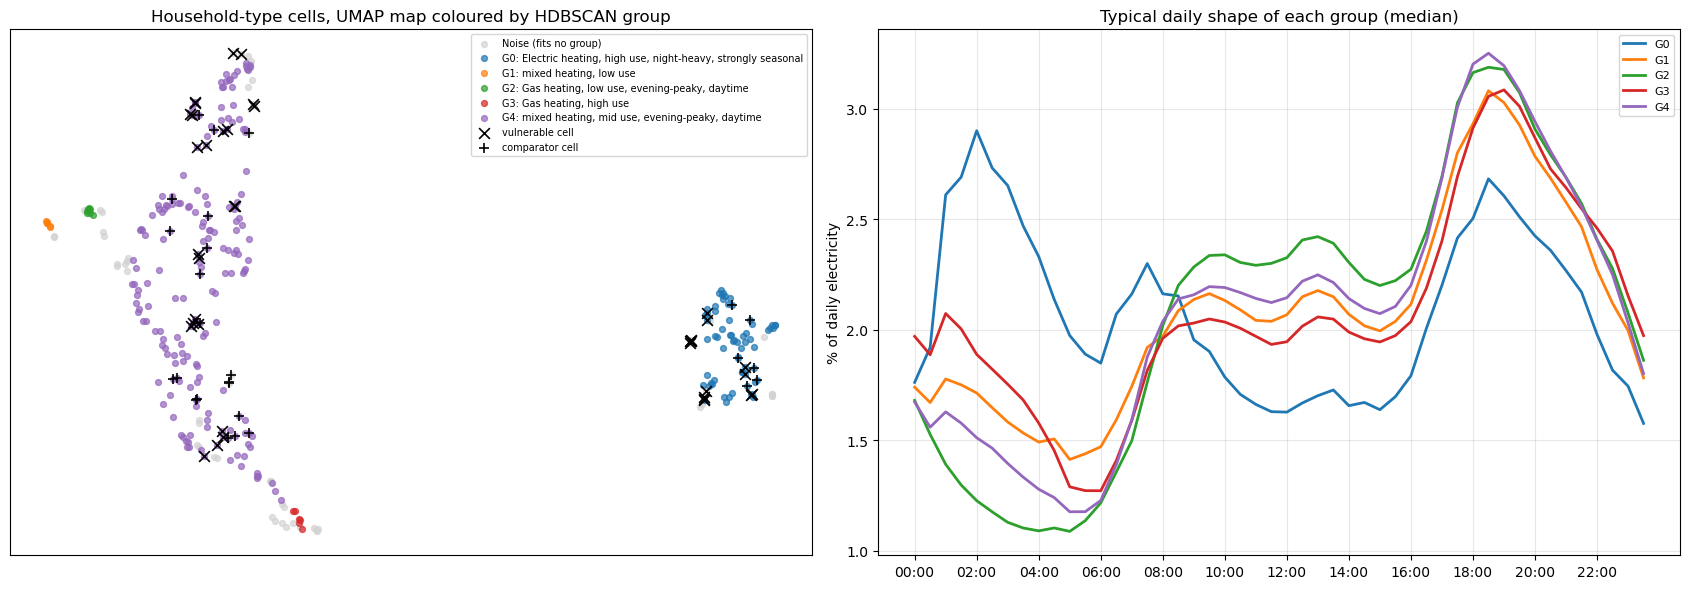

In [4]:
emb = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=42).fit_transform(Z)
fig, axes = plt.subplots(1, 2, figsize=(17, 6))
ax = axes[0]
for g in sorted(labels.unique()):
    sel = (labels == g).to_numpy()
    ax.scatter(emb[sel, 0], emb[sel, 1], s=18, alpha=0.7, label=names[g], color="lightgrey" if g == -1 else None)
for r, mark in (("vulnerable", "x"), ("comparator", "+")):
    sel = role.eq(r).to_numpy()
    ax.scatter(emb[sel, 0], emb[sel, 1], s=60, marker=mark, color="black", linewidths=1.2, label=f"{r} cell")
ax.set_title("Household-type cells, UMAP map coloured by HDBSCAN group"); ax.legend(fontsize=7, loc="best")
ax.set_xticks([]); ax.set_yticks([])
ax = axes[1]
for g in sorted(labels.unique()):
    if g >= 0:
        ax.plot(range(48), share[labels == g].median().to_numpy() * 100, linewidth=2, label=names[g].split(":")[0])
ax.set_xticks(range(0, 48, 4), [f"{x:02d}:00" for x in range(0, 24, 2)])
ax.set_ylabel("% of daily electricity"); ax.set_title("Typical daily shape of each group (median)")
ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### Beyond heating fuel and solar

Heating fuel and PV dominate the groupings above. To ask whether *deprivation-related* cells share a pattern of their own, each feature is re-centred within its heating-fuel × PV stratum (removing those effects) and HDBSCAN is run again. Then vulnerable and comparator cells are compared feature by feature.


In [5]:
A = F - F.groupby(stratum).transform("mean")
ZA = StandardScaler().fit_transform(A)
adj = [(mcs, ms, hdbscan.HDBSCAN(min_cluster_size=mcs, min_samples=ms, gen_min_span_tree=True).fit(ZA))
       for mcs in (5, 8, 10) for ms in (3, 5)]
best_adj = max(adj, key=lambda t: t[2].relative_validity_)
print(f"Adjusted features: best DBCV = {best_adj[2].relative_validity_:.3f} "
      f"({best_adj[2].labels_.max() + 1} groups, {100 * (best_adj[2].labels_ == -1).mean():.0f}% noise) "
      f"vs {best.DBCV:.3f} before adjustment")

rows = []
for col in A.columns:
    a, b = A[role.eq("vulnerable")][col], A[role.eq("comparator")][col]
    rows.append({"feature": col, "vulnerable (mean, adjusted)": a.mean(), "comparator (mean, adjusted)": b.mean(),
                 "Mann–Whitney p": mannwhitneyu(a, b).pvalue})
print(f"\nVulnerable ({role.eq('vulnerable').sum()} cells) vs comparator ({role.eq('comparator').sum()} cells), within heating fuel x PV")
print(pd.DataFrame(rows).round(4).to_string(index=False))

Adjusted features: best DBCV = 0.017 (3 groups, 28% noise) vs 0.175 before adjustment

Vulnerable (38 cells) vs comparator (26 cells), within heating fuel x PV
         feature  vulnerable (mean, adjusted)  comparator (mean, adjusted)  Mann–Whitney p
     log kWh/day                      -0.0438                      -0.0010          0.1571
     night 00–06                       0.0253                      -0.0022          0.5073
   morning 06–09                      -0.0024                       0.0006          0.0744
       day 09–16                      -0.0084                      -0.0025          0.4319
   evening 16–19                      -0.0059                       0.0006          0.3706
   winter/summer                       0.0214                      -0.0256          0.4814
change 2021→23 %                       1.5452                      -0.1040          0.0384


## 2. Energy-poverty signals

**2a. Did the sample change?** The number of SERL households roughly tripled from 2020 to 2021. If the households who joined use less, part of the apparent fall in demand is a change in *who* is measured. The check: recompute each change holding the mix of groups fixed at the earlier year's shares (by deprivation, tenure, building type, region, floor area and occupants). If the fixed-mix change is close to the raw change, composition does not explain it.


In [6]:
MIX_BY = ["IMD_quintile", "tenure", "building_type", "region", "floor_area_m2", "num_occupants"]
rows = []
for q in (ELEC, GAS):
    w = su.select_slice(yearly, q, "kWh/day").set_index("year")
    for a, b in ((2020, 2021), (2021, 2022), (2021, 2023)):
        row = {"quantity": q, "period": f"{a}→{b}", f"households (start)": int(w.loc[a, "n_rounded"]),
               "households (end)": int(w.loc[b, "n_rounded"]), "raw change %": 100 * (w.loc[b, "mean"] / w.loc[a, "mean"] - 1)}
        for s in MIX_BY:
            d = su.select_slice(yearly, q, "kWh/day", segment=s)
            d = d[~d["segment_3_value"].astype(str).isin(["All", "nan"])]
            p = d.pivot(index="segment_3_value", columns="year", values="mean")
            n = d.pivot(index="segment_3_value", columns="year", values="n_rounded")
            ok = p[[a, b]].notna().all(axis=1)
            wt = n.loc[ok, a] / n.loc[ok, a].sum()
            row[f"fixed mix: {s}"] = 100 * ((wt * p.loc[ok, b]).sum() / (wt * p.loc[ok, a]).sum() - 1)
        rows.append(row)
composition = pd.DataFrame(rows)
print("Change in mean kWh/day: raw vs holding the group mix fixed at the start year (%)")
print(composition.round(1).to_string(index=False))
composition.to_csv(OUT / "composition_check.csv", index=False)

Change in mean kWh/day: raw vs holding the group mix fixed at the start year (%)
           quantity    period  households (start)  households (end)  raw change %  fixed mix: IMD_quintile  fixed mix: tenure  fixed mix: building_type  fixed mix: region  fixed mix: floor_area_m2  fixed mix: num_occupants
Electricity imports 2020→2021                3720             10790          -7.6                     -6.5               -7.1                      -7.0               -7.0                      -5.7                      -8.1
Electricity imports 2021→2022               10790              8880         -13.2                    -13.2              -13.3                     -13.0              -13.2                     -12.3                     -13.3
Electricity imports 2021→2023               10790              8830         -15.8                    -15.8              -15.8                     -15.5              -15.9                     -14.4                     -16.2
                Gas 2020→20

**2b. Under-consumption, winter rise, the 2022 cut-back and heating strain** for the named groups.
- *Use per household, per m² and per person (2023).* Lower use per m² in homes that are not more efficient can indicate under-heating.
- *Winter rise (2023):* Dec–Feb minus Jun–Aug, kWh/day.
- *Weather-normalised change:* for each year, use is regressed on that year's monthly heating degree days and evaluated at the group's normal (2020–2023 average) weather, so the 2021→2022 and 2021→2023 changes are not driven by mild or cold years.
- *Heating strain:* extra kWh/day per heating degree-day (slope over all 48 months).



Electricity imports
                        kWh/day  kWh/m²/day  kWh/person/day  winter rise kWh/day  normalised 2021→22 %  normalised 2021→23 %  kWh/day per HDD
group                                                                                                                                        
All households             8.51        0.09            4.18                 3.40                -11.03                -13.74             0.45
IMD 1 (most deprived)      7.22        0.10            3.82                 2.45                -12.05                -13.83             0.33
IMD 2                      7.94        0.10            4.04                 3.17                -10.17                -13.03             0.42
IMD 3                      8.83        0.09            4.36                 3.73                -12.42                -15.58             0.51
IMD 4                      9.03        0.09            4.35                 3.74                -11.89                -14.22   

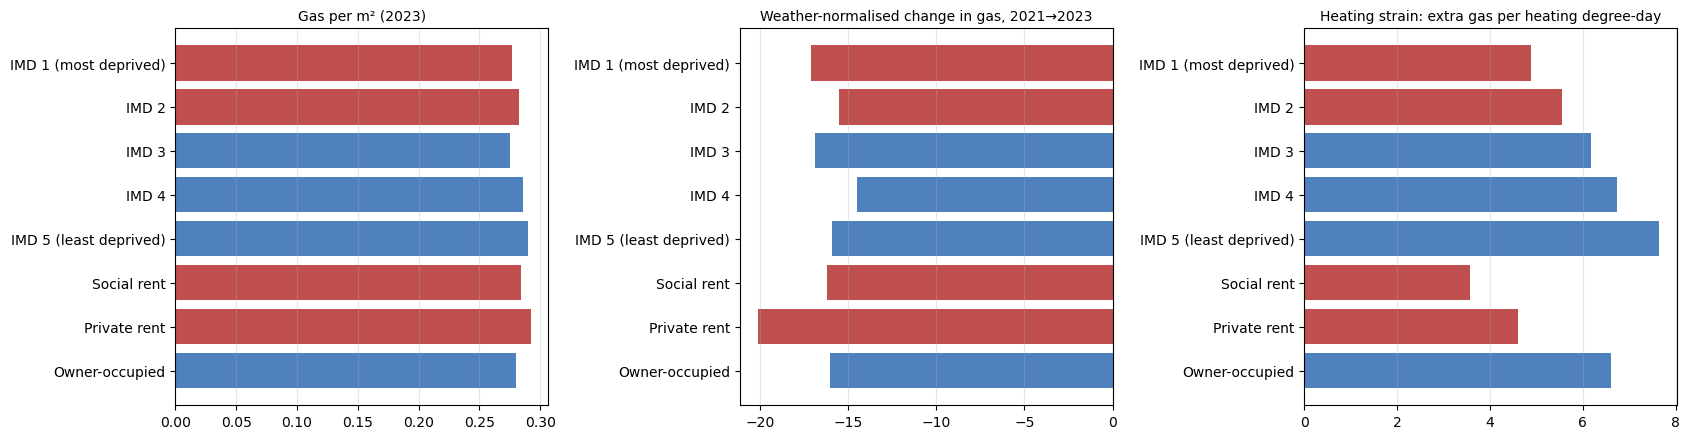

In [7]:
def normalised_change(q, f, years=(2021, 2022, 2023)):
    y = su.monthly_series(monthly, q, "kWh/day", **f)
    h = su.monthly_series(monthly, q, "kWh/day", value="mean_hdd", **f)
    if y.isna().any() or h.isna().any():
        return {}
    normal = h.groupby(h.index.month).mean()
    level = {}
    for yr in years:
        b, a = np.polyfit(h.loc[str(yr)], y.loc[str(yr)], 1)
        level[yr] = float((a + b * normal).mean())
    slope = np.polyfit(h, y, 1)[0]
    return {"2021→22 %": 100 * (level[2022] / level[2021] - 1), "2021→23 %": 100 * (level[2023] / level[2021] - 1),
            "kWh/day per HDD": slope}

y23 = yearly[yearly["year"].eq(2023)]
rows = []
for name, f in FOCUS.items():
    for q in (ELEC, GAS):
        r = {"group": name, "quantity": q}
        for unit, label in (("kWh/day", "kWh/day"), ("kWh/m2/day", "kWh/m²/day"), ("kWh/person/day", "kWh/person/day")):
            try:
                r[label] = su.select_slice(y23, q, unit, **f)["mean"].iloc[0]
            except ValueError:
                r[label] = np.nan
        m23 = su.monthly_series(monthly, q, "kWh/day", **f).loc["2023"]
        r["winter rise kWh/day"] = m23[m23.index.month.isin([12, 1, 2])].mean() - m23[m23.index.month.isin([6, 7, 8])].mean()
        r.update({f"normalised {k}" if "%" in k else k: v for k, v in normalised_change(q, f).items()})
        rows.append(r)
signals = pd.DataFrame(rows)
for q in (ELEC, GAS):
    print(f"\n{q}")
    print(signals[signals["quantity"].eq(q)].drop(columns="quantity").set_index("group").round(2).to_string())
signals.to_csv(OUT / "signals.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
imd = [k for k in FOCUS if k.startswith("IMD")]
ten = ["Social rent", "Private rent", "Owner-occupied"]
for ax, col, title in ((axes[0], "kWh/m²/day", "Gas per m² (2023)"),
                       (axes[1], "normalised 2021→23 %", "Weather-normalised change in gas, 2021→2023"),
                       (axes[2], "kWh/day per HDD", "Heating strain: extra gas per heating degree-day")):
    s = signals[signals["quantity"].eq(GAS)].set_index("group").loc[imd + ten, col]
    ax.barh(s.index, s.values, color=["#c0504d" if ("1" in g or "2" in g or "rent" in g) else "#4f81bd" for g in s.index])
    ax.invert_yaxis(); ax.set_title(title, fontsize=10); ax.grid(axis="x", alpha=0.3)
plt.tight_layout(); plt.show()

**2c. Who has the assets that dynamic tariffs reward?** Shares of households with solar PV and with electric heating, from SERL's household counts in each group. PV shares use **2021**: in 2022–2023 SERL's daily statistics cover only 20–40 PV homes (export readings are missing), so later counts would wrongly suggest almost no PV.


In [8]:
y21 = yearly[yearly["year"].eq(2021)]
pv_all = su.select_slice(y21, ELEC, "kWh/day", pv="Yes")["n_rounded"].iloc[0]
print(f"PV homes in SERL daily statistics: 2021 {pv_all:.0f}; 2023 {su.select_slice(y23, ELEC, 'kWh/day', pv='Yes')['n_rounded'].iloc[0]:.0f}")
rows = []
for s, label in (("IMD_quintile", "IMD quintile"), ("tenure", "tenure"), ("currentEnergyRating", "EPC band"), ("building_type", "building type")):
    base = su.select_slice(y23, ELEC, "kWh/day", segment=s).set_index("segment_3_value")["n_rounded"]
    base21 = su.select_slice(y21, ELEC, "kWh/day", segment=s).set_index("segment_3_value")["n_rounded"]
    pv = su.select_slice(y21, ELEC, "kWh/day", pv="Yes", segment=s).set_index("segment_3_value")["n_rounded"]
    el = su.select_slice(y23, ELEC, "kWh/day", fuel="Electric", segment=s).set_index("segment_3_value")["n_rounded"]
    for lv in base.index:
        if str(lv) in ("All", "nan", "No data", "No answer"):
            continue
        rows.append({"characteristic": label, "level": lv, "households 2023": base[lv],
                     "with PV % (2021)": 100 * pv.get(lv, np.nan) / base21.get(lv, np.nan),
                     "electric heating % (2023)": 100 * el.get(lv, np.nan) / base[lv]})
assets = pd.DataFrame(rows)
print(assets.round(1).to_string(index=False))
assets.to_csv(OUT / "asset_access.csv", index=False)

PV homes in SERL daily statistics: 2021 680; 2023 20
characteristic                            level  households 2023  with PV % (2021)  electric heating % (2023)
  IMD quintile                                1             1790               3.6                        7.8
  IMD quintile                                2             2040               5.3                        6.9
  IMD quintile                                3             1700               7.0                        6.5
  IMD quintile                                4             1640               8.5                        4.3
  IMD quintile                                5             1660               8.1                        1.8
        tenure         Own outright or mortgage             6840               7.3                        4.4
        tenure               Part-own part-rent               70               0.0                        0.0
        tenure                     Private rent              640   

## 3. SARIMA forecasts of 2024 use

For each named group, SARIMA(1,0,0)(0,1,1)₁₂ (the specification evaluated in `TemporalForecasting.ipynb`) is first trained on 2020–2022 and tested on 2023, against a seasonal-naive forecast, then refitted on all 48 months to forecast 2024 with 95% intervals. The 2024 electricity forecasts feed the tariff analysis in part 4.


Electricity imports: SARIMA beats seasonal naive on 2023 in 7 of 16 groups (median MAPE 4.9% vs 4.6%)
Gas: SARIMA beats seasonal naive on 2023 in 0 of 16 groups (median MAPE 26.0% vs 15.6%)

Electricity imports
                        2023 test MAPE %  seasonal naive MAPE %  2023 actual kWh/day  2024 forecast kWh/day  2024 low (95%)  2024 high (95%)  change %
group                                                                                                                                                 
All households                      4.48                   4.47                 8.50                   8.52            6.89            10.15      0.24
IMD 1 (most deprived)               4.96                   3.15                 7.14                   7.16            5.81             8.50      0.27
IMD 2                               4.61                   4.46                 7.89                   7.93            6.35             9.52      0.61
IMD 3                             

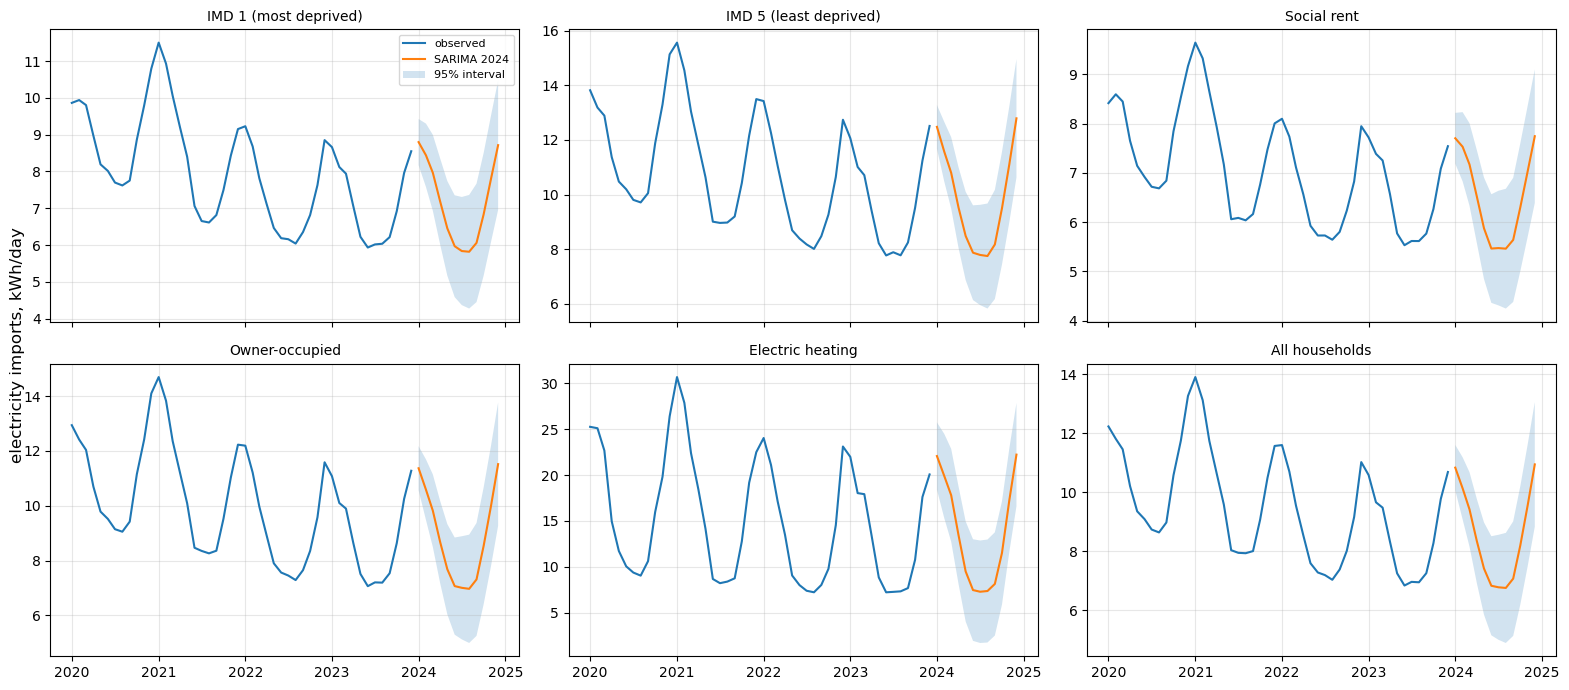

In [9]:
def sarima(y):
    return SARIMAX(y, order=(1, 0, 0), seasonal_order=(0, 1, 1, 12)).fit(disp=False)

rows, forecast_2024 = [], {}
for name, f in FOCUS.items():
    for q in (ELEC, GAS):
        y = su.monthly_series(monthly, q, "kWh/day", **f)
        if y.isna().any():
            continue
        train, test = y.loc[:"2022"], y.loc["2023"]
        pred = sarima(train).forecast(12).to_numpy()
        naive = train.iloc[-12:].to_numpy()
        fc = sarima(y).get_forecast(12)
        mean, ci = fc.predicted_mean, fc.conf_int(alpha=0.05)
        if q == ELEC:
            forecast_2024[name] = mean
        rows.append({"group": name, "quantity": q,
                     "2023 test MAPE %": 100 * np.mean(np.abs(test.to_numpy() - pred) / test.to_numpy()),
                     "seasonal naive MAPE %": 100 * np.mean(np.abs(test.to_numpy() - naive) / test.to_numpy()),
                     "2023 actual kWh/day": test.mean(), "2024 forecast kWh/day": mean.mean(),
                     "2024 low (95%)": ci.iloc[:, 0].mean(), "2024 high (95%)": ci.iloc[:, 1].mean()})
fc_table = pd.DataFrame(rows)
fc_table["change %"] = 100 * (fc_table["2024 forecast kWh/day"] / fc_table["2023 actual kWh/day"] - 1)
for q in (ELEC, GAS):
    t = fc_table[fc_table["quantity"].eq(q)]
    better = (t["2023 test MAPE %"] < t["seasonal naive MAPE %"]).sum()
    print(f"{q}: SARIMA beats seasonal naive on 2023 in {better} of {len(t)} groups "
          f"(median MAPE {t['2023 test MAPE %'].median():.1f}% vs {t['seasonal naive MAPE %'].median():.1f}%)")
for q in (ELEC, GAS):
    print(f"\n{q}")
    print(fc_table[fc_table["quantity"].eq(q)].drop(columns="quantity").set_index("group").round(2).to_string())
fc_table.to_csv(OUT / "sarima_2024.csv", index=False)

show = ["IMD 1 (most deprived)", "IMD 5 (least deprived)", "Social rent", "Owner-occupied", "Electric heating", "All households"]
fig, axes = plt.subplots(2, 3, figsize=(16, 7), sharex=True)
for ax, name in zip(axes.flat, show):
    y = su.monthly_series(monthly, ELEC, "kWh/day", **FOCUS[name])
    fc = sarima(y).get_forecast(12); ci = fc.conf_int(alpha=0.05)
    ax.plot(y.index, y.to_numpy(), label="observed")
    ax.plot(fc.predicted_mean.index, fc.predicted_mean.to_numpy(), label="SARIMA 2024")
    ax.fill_between(ci.index, ci.iloc[:, 0], ci.iloc[:, 1], alpha=0.2, label="95% interval")
    ax.set_title(name, fontsize=10); ax.grid(alpha=0.3)
axes.flat[0].legend(fontsize=8); fig.supylabel("electricity imports, kWh/day")
plt.tight_layout(); plt.show()

## 4. 2024 tariffs: who gains from dynamic pricing?

Each group's 2024 consumption = its 2023 half-hourly *shape* (weekday/weekend for the whole sample) scaled to its **SARIMA 2024 monthly forecast**. It is priced with **real 2024 rates** for GSP region C: Agile (half-hourly) and Flexible Octopus (flat, direct debit), each with its standing charge. 2024 had no Energy Price Guarantee, so the whole year is a clean comparison.

Scenarios (load shifting moves part of the 16:00–19:00 use into each day's 8 cheapest half-hours):
- **A – Everyone on the flat tariff.**
- **B – Everyone on Agile, no shifting.**
- **C – Flexibility gap:** vulnerable groups on Agile but unable to shift (0%); comparators on Agile shifting 30%.
- **D – Access gap:** vulnerable groups stay on the flat tariff (e.g. prepayment meters or no smart meter, which rule out Agile); comparators on Agile shifting 30%.

C and D are assumptions about *ability* to shift or switch, not measured behaviour. They show how much those barriers alone could matter.


In [10]:
START, END = "2024-01-01", "2025-01-01"
REGION = "C"
agile = tu.half_hourly_rates(tu.fetch_unit_rates(tu.AGILE_PRODUCT_2024, tu.agile_code(REGION, tu.AGILE_PRODUCT_2024), START, END), START, END)
flat = tu.half_hourly_rates(tu.fetch_unit_rates(tu.FLEX_PRODUCT, tu.flex_code(REGION), START, END), START, END)
st_agile = tu.daily_standing_charges(tu.fetch_standing_charges(tu.AGILE_PRODUCT_2024, tu.agile_code(REGION, tu.AGILE_PRODUCT_2024), START, END), START, END)
st_flat = tu.daily_standing_charges(tu.fetch_standing_charges(tu.FLEX_PRODUCT, tu.flex_code(REGION), START, END), START, END)
q = agile.index.tz_convert(tu.UK_TZ).quarter
print("2024 mean unit rate by quarter (p/kWh inc. VAT)")
print(pd.DataFrame({"Agile": agile.groupby(q).mean(), "Flexible (flat)": flat.groupby(q).mean()}).round(2).to_string())
print(f"Standing charges (p/day): Agile {sorted(np.round(st_agile.unique(), 2))}, flat {sorted(np.round(st_flat.unique(), 2))}")
idx24 = tu.half_hour_index(START, END)

2024 mean unit rate by quarter (p/kWh inc. VAT)
   Agile  Flexible (flat)
1  15.13            29.73
2  15.43            25.72
3  15.99            23.53
4  20.54            25.68
Standing charges (p/day): Agile [34.79], flat [36.53, 38.72, 39.54]


In [11]:
def consumption_2024(name):
    f = FOCUS[name]
    profiles = {"both": su.daily_profile(hh, 2023, ELEC, "Wh", to_kwh=True, **f)}
    if not f:   # whole sample has weekday / weekend shapes
        profiles.update({d: su.daily_profile(hh, 2023, ELEC, "Wh", to_kwh=True, weekday_weekend=d) for d in ("weekday", "weekend")})
    level = forecast_2024[name]
    level.index = pd.DatetimeIndex(level.index)
    return tu.build_consumption(profiles, level, idx24)

kwh24, rows = {}, []
for name in forecast_2024:
    k = kwh24[name] = consumption_2024(name)
    bf, ba = tu.bill(k, flat, st_flat), tu.bill(k, agile, st_agile)
    bs = tu.bill(tu.shift_peak(k, agile, 0.3), agile, st_agile)
    t = k.index.tz_convert(tu.UK_TZ).strftime("%H:%M")
    rows.append({"group": name, "kWh/year": bf["kwh"], "peak 16–19 share %": 100 * k[(t >= "16:00") & (t < "19:00")].sum() / k.sum(),
                 "flat £": bf["total_gbp"], "standing share of flat bill %": 100 * bf["standing_gbp"] / bf["total_gbp"],
                 "Agile £": ba["total_gbp"], "Agile saving %": 100 * (1 - ba["total_gbp"] / bf["total_gbp"]),
                 "Agile + 30% shift £": bs["total_gbp"],
                 "flat p/kWh (all-in)": 100 * bf["total_gbp"] / bf["kwh"], "Agile p/kWh (all-in)": 100 * ba["total_gbp"] / ba["kwh"]})
bills = pd.DataFrame(rows).set_index("group")
print("2024 electricity bills from SARIMA forecasts, region C prices (all-in p/kWh includes standing charges)")
print(bills.round(2).to_string())

# sensitivity: same calculation with each group's 2023 actual monthly use instead of the SARIMA forecast
diff = []
for name in forecast_2024:
    f = FOCUS[name]
    level23 = su.monthly_series(monthly, ELEC, "kWh/day", **f).loc["2023"]
    level23.index = pd.date_range("2024-01-01", periods=12, freq="MS")
    profiles = {"both": su.daily_profile(hh, 2023, ELEC, "Wh", to_kwh=True, **f)}
    if not f:
        profiles.update({d: su.daily_profile(hh, 2023, ELEC, "Wh", to_kwh=True, weekday_weekend=d) for d in ("weekday", "weekend")})
    k = tu.build_consumption(profiles, level23, idx24)
    bf, ba = tu.bill(k, flat, st_flat), tu.bill(k, agile, st_agile)
    diff.append({"group": name, "Agile saving % (2023 levels)": 100 * (1 - ba["total_gbp"] / bf["total_gbp"]),
                 "Agile p/kWh (2023 levels)": 100 * ba["total_gbp"] / ba["kwh"]})
diff = pd.DataFrame(diff).set_index("group")
print(f"\nSensitivity: using 2023 actual use instead of the SARIMA forecast changes Agile saving by at most "
      f"{(diff['Agile saving % (2023 levels)'] - bills['Agile saving %']).abs().max():.2f} percentage points and the all-in "
      f"Agile price by at most {(diff['Agile p/kWh (2023 levels)'] - bills['Agile p/kWh (all-in)']).abs().max():.2f} p/kWh")
bills.to_csv(OUT / "bills_2024.csv")

2024 electricity bills from SARIMA forecasts, region C prices (all-in p/kWh includes standing charges)
                        kWh/year  peak 16–19 share %   flat £  standing share of flat bill %  Agile £  Agile saving %  Agile + 30% shift £  flat p/kWh (all-in)  Agile p/kWh (all-in)
group                                                                                                                                                                                
All households           3117.49               15.23   965.07                          14.56   679.80           29.56               648.59                30.96                 21.81
IMD 1 (most deprived)    2618.61               15.61   832.45                          16.88   592.42           28.83               565.67                31.79                 22.62
IMD 2                    2902.61               15.27   908.38                          15.46   641.84           29.34               612.74                31.30          


Sensitivity: using 2023 actual use instead of the SARIMA forecast changes Agile saving by at most 0.60 percentage points and the all-in Agile price by at most 0.31 p/kWh


2024 annual electricity bill and all-in price per kWh under each scenario
                                           pair                   scenario  vulnerable £  comparator £  vulnerable p/kWh  comparator p/kWh  price gap p/kWh  vulnerable pays per kWh vs comparator %
IMD 1 (most deprived) vs IMD 5 (least deprived)            A everyone flat        832.45       1090.60             31.79             30.36             1.43                                     4.73
IMD 1 (most deprived) vs IMD 5 (least deprived) B everyone Agile, no shift        592.42        764.31             22.62             21.27             1.35                                     6.35
IMD 1 (most deprived) vs IMD 5 (least deprived)          C flexibility gap        592.42        728.55             22.62             20.28             2.35                                    11.57
IMD 1 (most deprived) vs IMD 5 (least deprived)               D access gap        832.45        728.55             31.79             20.28

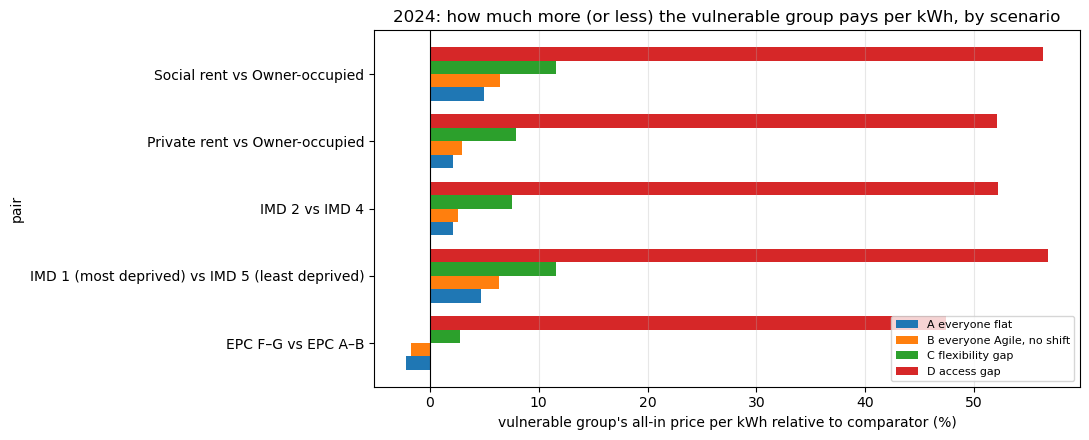

In [12]:
PAIRS = [("IMD 1 (most deprived)", "IMD 5 (least deprived)"), ("IMD 2", "IMD 4"), ("Social rent", "Owner-occupied"),
         ("Private rent", "Owner-occupied"), ("EPC F–G", "EPC A–B")]
def cost(name, tariff, shift=0.0):
    k = kwh24[name]
    if tariff == "flat":
        b = tu.bill(k, flat, st_flat)
    else:
        b = tu.bill(tu.shift_peak(k, agile, shift) if shift else k, agile, st_agile)
    return b["total_gbp"], 100 * b["total_gbp"] / b["kwh"]

SCEN = {"A everyone flat": (("flat", 0), ("flat", 0)),
        "B everyone Agile, no shift": (("agile", 0), ("agile", 0)),
        "C flexibility gap": (("agile", 0), ("agile", 0.3)),
        "D access gap": (("flat", 0), ("agile", 0.3))}
rows = []
for vul, comp in PAIRS:
    for sname, ((tv, sv), (tc, sc)) in SCEN.items():
        bv, pv_ = cost(vul, tv, sv); bc, pc = cost(comp, tc, sc)
        rows.append({"pair": f"{vul} vs {comp}", "scenario": sname, "vulnerable £": bv, "comparator £": bc,
                     "vulnerable p/kWh": pv_, "comparator p/kWh": pc, "price gap p/kWh": pv_ - pc,
                     "vulnerable pays per kWh vs comparator %": 100 * (pv_ / pc - 1)})
scen = pd.DataFrame(rows)
print("2024 annual electricity bill and all-in price per kWh under each scenario")
print(scen.round(2).to_string(index=False))
scen.to_csv(OUT / "scenarios_2024.csv", index=False)

pivot = scen.pivot(index="pair", columns="scenario", values="vulnerable pays per kWh vs comparator %")
fig, ax = plt.subplots(figsize=(11, 4.5))
pivot.plot(kind="barh", ax=ax, width=0.8)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("vulnerable group's all-in price per kWh relative to comparator (%)")
ax.set_title("2024: how much more (or less) the vulnerable group pays per kWh, by scenario")
ax.legend(fontsize=8, loc="lower right"); ax.grid(axis="x", alpha=0.3)
plt.tight_layout(); plt.show()

### The HDBSCAN groups at 2024 prices

Each cell from part 1 is priced at 2024 rates with its own 2023 half-hourly shape and 2023 monthly use ("2023 use at 2024 prices"), to see which natural groups gain most from Agile.


                                                                count  mean   min   50%   max
group                                                                                        
G0: Electric heating, high use, night-heavy, strongly seasonal   65.0  33.8  31.9  33.7  35.6
G1: mixed heating, low use                                        6.0  28.4  28.4  28.4  28.5
G2: Gas heating, low use, evening-peaky, daytime                  7.0  26.7  26.5  26.5  27.0
G3: Gas heating, high use                                         6.0  31.4  31.2  31.3  31.8
G4: mixed heating, mid use, evening-peaky, daytime              193.0  28.9  27.7  28.9  30.8
Noise (fits no group)                                            60.0  31.1  27.0  30.5  39.4

            count  mean   min   50%   max
role                                     
comparator   26.0  30.2  28.1  29.5  34.2
other       273.0  30.1  26.5  29.2  35.8
vulnerable   38.0  31.4  27.7  29.4  39.4

Vulnerable vs comparator cells: Mann

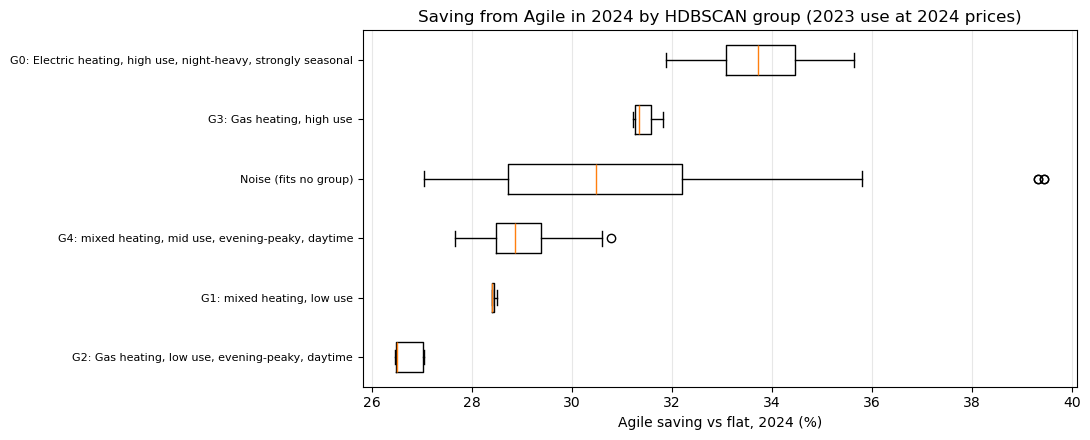

In [13]:
rows = []
for key in idx:
    shape = prof.loc[key] / 1000
    shape.index = [f"{hh_ // 2:02d}:{30 * (hh_ % 2):02d}" for hh_ in shape.index]
    level = pd.Series(mon.loc[key].to_numpy(), index=pd.date_range("2024-01-01", periods=12, freq="MS"))
    k = tu.build_consumption({"both": shape}, level, idx24)
    bf, ba = tu.bill(k, flat, st_flat), tu.bill(k, agile, st_agile)
    rows.append({"group": group_name[key], "role": role[key], "Agile saving %": 100 * (1 - ba["total_gbp"] / bf["total_gbp"])})
cell_bills = pd.DataFrame(rows, index=idx)
print(cell_bills.groupby("group")["Agile saving %"].describe()[["count", "mean", "min", "50%", "max"]].round(1).to_string())
print()
print(cell_bills.groupby("role")["Agile saving %"].describe()[["count", "mean", "min", "50%", "max"]].round(1).to_string())
v, c_ = cell_bills.loc[role.eq("vulnerable"), "Agile saving %"], cell_bills.loc[role.eq("comparator"), "Agile saving %"]
print(f"\nVulnerable vs comparator cells: Mann–Whitney p = {mannwhitneyu(v, c_).pvalue:.3f}")
cell_bills.to_csv(OUT / "hdbscan_cells_bills_2024.csv")

fig, ax = plt.subplots(figsize=(11, 4.5))
order = cell_bills.groupby("group")["Agile saving %"].median().sort_values().index
ax.boxplot([cell_bills.loc[cell_bills["group"].eq(g), "Agile saving %"] for g in order], vert=False, labels=order)
ax.set_xlabel("Agile saving vs flat, 2024 (%)"); ax.set_title("Saving from Agile in 2024 by HDBSCAN group (2023 use at 2024 prices)")
ax.grid(axis="x", alpha=0.3); ax.tick_params(axis="y", labelsize=8)
plt.tight_layout(); plt.show()

## 5. The crisis test: what if a household had been on Agile in 2022?

2023 and 2024 were calm years in which Agile was cheap. In 2022 wholesale prices spiked, so this is where the original hypothesis (that dynamic pricing hurts households who cannot adapt) is most likely to hold.

**Period:** April–December 2022, the months for which the crisis-era Agile products have published prices.
**Consumption:** each group's actual SERL 2022 half-hourly shape and 2022 monthly use.
**Agile:** *Agile Octopus August 2022* (prices capped at 78p/kWh), the product a household joining at the height of the crisis would have had, with *July 2022* (capped at 55p) for comparison. Octopus publishes these products' half-hourly prices from April 2022, before they went on sale (29 August and 22 July). April–August therefore shows **what Agile's pricing would have cost** in the crisis, with each product's standing charge applied from April. As a check, the bills are also given for **September–December only**, when the August 2022 product was actually available. The original 2018 Agile, capped at 35p, protected existing customers and is not representative of joining in 2022.
**Flat tariff:** Octopus's published April–September 2022 flat rate (11.78p) is clearly an error in the API: the price cap was far higher. It is replaced by the national price-cap figures widely reported for that period (**28.34p/kWh, 45.34p/day**). Those are *higher* than London's (about 28p and 31p), so they flatter Agile: the test is conservative. October–December uses Octopus's London rate (35.8p, 31.51p/day, the Energy Price Guarantee level). The £400 Energy Bills Support Scheme credit applied to every household on either tariff, so it is left out.


In [14]:
S22, E22 = "2022-04-01", "2023-01-01"
AGILE_22 = {"Agile Aug-2022 (78p cap)": "AGILE-22-08-31", "Agile Jul-2022 (55p cap)": "AGILE-22-07-22"}
agile22, st_agile22 = {}, {}
for label, product in AGILE_22.items():
    agile22[label] = tu.half_hourly_rates(tu.fetch_unit_rates(product, tu.agile_code(REGION, product), S22, E22), S22, E22)
    st = tu.fetch_standing_charges(product, tu.agile_code(REGION, product), S22, E22)
    # the product launched mid-2022 and its (single, constant) standing charge is published from launch;
    # apply that same charge from April so the whole period can be priced
    st.loc[st["valid_from"].idxmin(), "valid_from"] = pd.Timestamp(S22, tz=tu.UK_TZ).tz_convert("UTC")
    st_agile22[label] = tu.daily_standing_charges(st, S22, E22)

def flat_2022(unit_q2q3=28.34, standing_q2q3=45.34):
    """Flat tariff Apr–Dec 2022: price cap (Apr–Sep, national figures) then EPG London rate (Oct–Dec)."""
    bounds = pd.to_datetime(["2022-04-01", "2022-10-01", "2023-01-01"]).tz_localize(tu.UK_TZ).tz_convert("UTC")
    units = pd.DataFrame({"valid_from": bounds[:2], "valid_to": bounds[1:], "p_inc_vat": [unit_q2q3, 35.80]})
    stand = pd.DataFrame({"valid_from": bounds[:2], "valid_to": bounds[1:], "p_inc_vat": [standing_q2q3, 31.51]})
    return tu.half_hourly_rates(units, S22, E22), tu.daily_standing_charges(stand, S22, E22)

flat22, st_flat22 = flat_2022()
idx22 = tu.half_hour_index(S22, E22)
m22 = agile22["Agile Aug-2022 (78p cap)"].index.tz_convert(tu.UK_TZ).to_period("M")
prices22 = pd.DataFrame({k: v.groupby(m22).mean() for k, v in agile22.items()} | {"flat": flat22.groupby(m22).mean()})
print("Mean unit price by month, 2022 (p/kWh inc. VAT)")
print(prices22.round(1).to_string())

Mean unit price by month, 2022 (p/kWh inc. VAT)
         Agile Aug-2022 (78p cap)  Agile Jul-2022 (55p cap)  flat
2022-04                      38.8                      38.3  28.3
2022-05                      27.6                      27.6  28.3
2022-06                      34.6                      33.9  28.3
2022-07                      51.6                      47.1  28.3
2022-08                      67.1                      53.1  28.3
2022-09                      55.1                      48.4  28.3
2022-10                      25.2                      24.8  35.8
2022-11                      27.1                      25.9  35.8
2022-12                      38.9                      32.6  35.8


In [15]:
hh22 = su.load_half_hourly([2022])
def consumption_2022(name):
    f = FOCUS[name]
    profiles = {"both": su.daily_profile(hh22, 2022, ELEC, "Wh", to_kwh=True, **f)}
    if not f:
        profiles.update({d: su.daily_profile(hh22, 2022, ELEC, "Wh", to_kwh=True, weekday_weekend=d) for d in ("weekday", "weekend")})
    return tu.build_consumption(profiles, su.monthly_series(monthly, ELEC, "kWh/day", **f), idx22)

AG = "Agile Aug-2022 (78p cap)"
kwh22, rows, monthly_bills = {}, [], {}
for name in FOCUS:
    k = kwh22[name] = consumption_2022(name)
    bf = tu.bill(k, flat22, st_flat22)
    row = {"group": name, "kWh (Apr–Dec)": bf["kwh"], "flat £": bf["total_gbp"]}
    for label in AGILE_22:
        ba = tu.bill(k, agile22[label], st_agile22[label])
        row[f"{label} £"] = ba["total_gbp"]
        row[f"{label}: extra vs flat %"] = 100 * (ba["total_gbp"] / bf["total_gbp"] - 1)
    bs = tu.bill(tu.shift_peak(k, agile22[AG], 0.3), agile22[AG], st_agile22[AG])
    row["Aug-2022 Agile + 30% shift: extra vs flat %"] = 100 * (bs["total_gbp"] / bf["total_gbp"] - 1)
    rows.append(row)
    monthly_bills[name] = tu.compare(k, {"flat": (flat22, st_flat22), "Agile": (agile22[AG], st_agile22[AG])}, by="M") \
                            .pivot(index="period", columns="tariff", values="total_gbp")
bills22 = pd.DataFrame(rows).set_index("group")
# realism check: only the months when the Aug-2022 product was on sale
on_sale = idx22 >= pd.Timestamp("2022-09-01", tz=tu.UK_TZ).tz_convert("UTC")
bills22["Aug-2022 Agile, Sep–Dec only: extra vs flat %"] = [
    100 * (tu.bill(kwh22[n][on_sale], agile22[AG], st_agile22[AG])["total_gbp"]
           / tu.bill(kwh22[n][on_sale], flat22, st_flat22)["total_gbp"] - 1) for n in bills22.index]
print("Apr–Dec 2022 electricity bills, region C (positive % = Agile cost MORE than the flat tariff)")
print(bills22.round(1).to_string())
bills22.to_csv(OUT / "bills_2022_crisis.csv")

# sensitivity to the flat-rate assumption for Apr–Sep (London-like vs higher)
for unit, standing in ((26.0, 31.0), (28.34, 31.0), (32.0, 45.34)):
    fl, sf = flat_2022(unit, standing)
    extra = [100 * (tu.bill(kwh22[n], agile22[AG], st_agile22[AG])["total_gbp"] / tu.bill(kwh22[n], fl, sf)["total_gbp"] - 1) for n in FOCUS]
    print(f"flat Apr–Sep at {unit}p/kWh + {standing}p/day: Agile (Aug-2022) costs {min(extra):+.1f}% to {max(extra):+.1f}% vs flat across groups")

Apr–Dec 2022 electricity bills, region C (positive % = Agile cost MORE than the flat tariff)
                        kWh (Apr–Dec)  flat £  Agile Aug-2022 (78p cap) £  Agile Aug-2022 (78p cap): extra vs flat %  Agile Jul-2022 (55p cap) £  Agile Jul-2022 (55p cap): extra vs flat %  Aug-2022 Agile + 30% shift: extra vs flat %  Aug-2022 Agile, Sep–Dec only: extra vs flat %
group                                                                                                                                                                                                                                                                                  
All households                 2237.1   810.5                      1002.6                                       23.7                       913.2                                       12.7                                         20.6                                            6.6
IMD 1 (most deprived)          1883.2   699.0                      

flat Apr–Sep at 32.0p/kWh + 45.34p/day: Agile (Aug-2022) costs +11.2% to +17.1% vs flat across groups


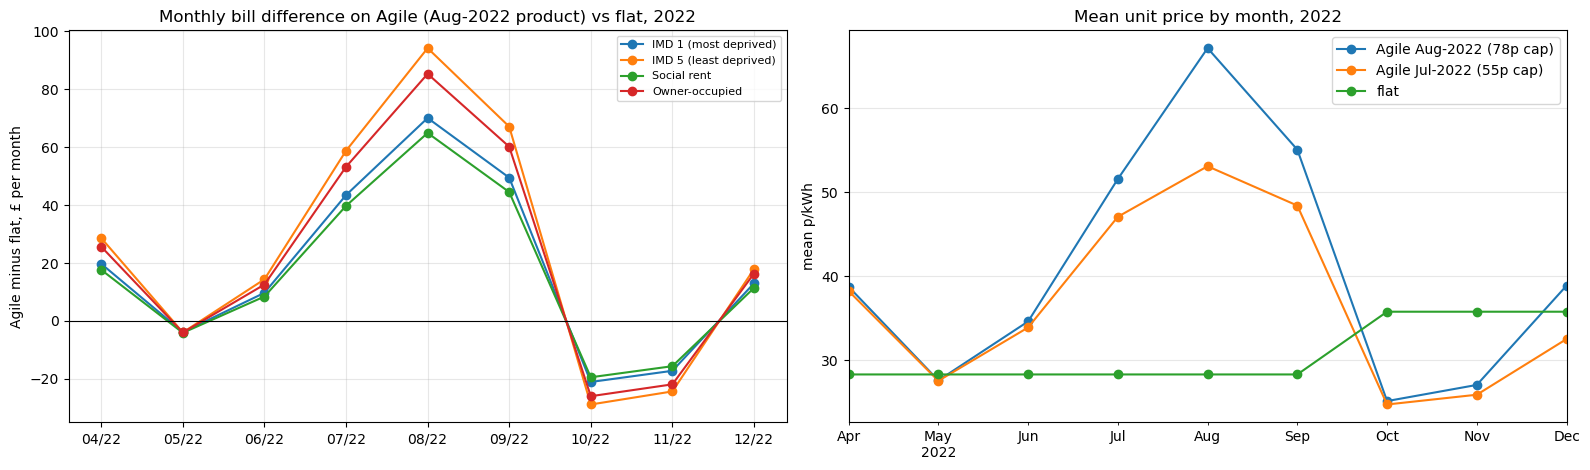

IMD 1 (most deprived): worst month 2022-08: Agile £137 vs flat £67 (+104%)
IMD 5 (least deprived): worst month 2022-08: Agile £179 vs flat £84 (+112%)
Social rent: worst month 2022-08: Agile £129 vs flat £64 (+102%)
Owner-occupied: worst month 2022-08: Agile £163 vs flat £78 (+109%)


In [16]:
pair = ["IMD 1 (most deprived)", "IMD 5 (least deprived)", "Social rent", "Owner-occupied"]
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
ax = axes[0]
for name in pair:
    mb = monthly_bills[name]
    ax.plot(range(len(mb)), (mb["Agile"] - mb["flat"]).to_numpy(), marker="o", label=name)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(range(len(mb)), [p[-2:] + "/22" for p in mb.index])
ax.set_ylabel("Agile minus flat, £ per month"); ax.set_title("Monthly bill difference on Agile (Aug-2022 product) vs flat, 2022")
ax.legend(fontsize=8); ax.grid(alpha=0.3)
ax = axes[1]
prices22.plot(ax=ax, marker="o")
ax.set_ylabel("mean p/kWh"); ax.set_title("Mean unit price by month, 2022"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

worst = {n: (monthly_bills[n]["Agile"] - monthly_bills[n]["flat"]).idxmax() for n in pair}
for n in pair:
    mb = monthly_bills[n]; m = worst[n]
    print(f"{n}: worst month {m}: Agile £{mb.loc[m, 'Agile']:.0f} vs flat £{mb.loc[m, 'flat']:.0f} "
          f"(+{100 * (mb.loc[m, 'Agile'] / mb.loc[m, 'flat'] - 1):.0f}%)")

In [17]:
def cost22(name, tariff, shift=0.0):
    k = kwh22[name]
    b = tu.bill(k, flat22, st_flat22) if tariff == "flat" else \
        tu.bill(tu.shift_peak(k, agile22[AG], shift) if shift else k, agile22[AG], st_agile22[AG])
    return b["total_gbp"], 100 * b["total_gbp"] / b["kwh"]

rows = []
for vul, comp in PAIRS:
    for sname, ((tv, sv), (tc, sc)) in SCEN.items():
        bv, pv_ = cost22(vul, tv, sv); bc, pc = cost22(comp, tc, sc)
        rows.append({"pair": f"{vul} vs {comp}", "scenario": sname, "vulnerable £": bv, "comparator £": bc,
                     "vulnerable p/kWh": pv_, "comparator p/kWh": pc,
                     "vulnerable pays per kWh vs comparator %": 100 * (pv_ / pc - 1)})
scen22 = pd.DataFrame(rows)
print("Apr–Dec 2022: same scenarios as part 4 (Agile = Aug-2022 product)")
print(scen22.round(2).to_string(index=False))
scen22.to_csv(OUT / "scenarios_2022_crisis.csv", index=False)

Apr–Dec 2022: same scenarios as part 4 (Agile = Aug-2022 product)
                                           pair                   scenario  vulnerable £  comparator £  vulnerable p/kWh  comparator p/kWh  vulnerable pays per kWh vs comparator %
IMD 1 (most deprived) vs IMD 5 (least deprived)            A everyone flat        699.00        915.82             37.12             35.60                                     4.27
IMD 1 (most deprived) vs IMD 5 (least deprived) B everyone Agile, no shift        862.32       1139.64             45.79             44.30                                     3.37
IMD 1 (most deprived) vs IMD 5 (least deprived)          C flexibility gap        862.32       1111.42             45.79             43.20                                     6.00
IMD 1 (most deprived) vs IMD 5 (least deprived)               D access gap        699.00       1111.42             37.12             43.20                                   -14.08
                                 I

Saving from Agile vs the flat tariff (%; negative = Agile cost more)
                        2022 (Apr–Dec, crisis)  2023 (Jul–Dec)  2024 (full year)
group                                                                           
All households                           -23.7            31.7              29.6
IMD 1 (most deprived)                    -23.4            31.0              28.8
IMD 2                                    -23.4            31.4              29.3
IMD 3                                    -23.8            31.8              29.7
IMD 4                                    -24.0            31.8              29.6
IMD 5 (least deprived)                   -24.4            32.0              29.9
Social rent                              -22.7            31.0              28.7
Private rent                             -23.3            31.2              29.1
Owner-occupied                           -24.0            31.7              29.6
EPC A–B                                 

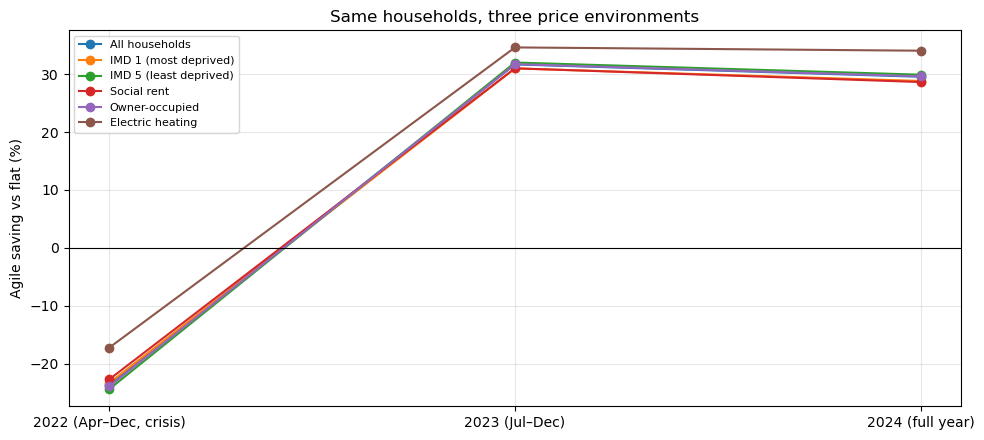

In [18]:
# the same groups in three price environments; 2023 = Jul–Dec (no Energy Price Guarantee distortion)
S23, E23 = "2023-07-01", "2024-01-01"
ag23 = tu.half_hourly_rates(tu.fetch_unit_rates(tu.AGILE_PRODUCT, tu.agile_code(REGION), "2023-01-01", "2024-01-01"), S23, E23)
fl23 = tu.half_hourly_rates(tu.fetch_unit_rates(tu.FLEX_PRODUCT, tu.flex_code(REGION), "2023-01-01", "2024-01-01"), S23, E23)
sa23 = tu.daily_standing_charges(tu.fetch_standing_charges(tu.AGILE_PRODUCT, tu.agile_code(REGION), "2023-01-01", "2024-01-01"), S23, E23)
sf23 = tu.daily_standing_charges(tu.fetch_standing_charges(tu.FLEX_PRODUCT, tu.flex_code(REGION), "2023-01-01", "2024-01-01"), S23, E23)
idx23 = tu.half_hour_index(S23, E23)
rows = []
for name in FOCUS:
    f = FOCUS[name]
    prof = {"both": su.daily_profile(hh, 2023, ELEC, "Wh", to_kwh=True, **f)}
    if not f:
        prof.update({d: su.daily_profile(hh, 2023, ELEC, "Wh", to_kwh=True, weekday_weekend=d) for d in ("weekday", "weekend")})
    k23 = tu.build_consumption(prof, su.monthly_series(monthly, ELEC, "kWh/day", **f), idx23)
    rows.append({"group": name,
                 "2022 (Apr–Dec, crisis)": -bills22.loc[name, f"{AG}: extra vs flat %"],
                 "2023 (Jul–Dec)": 100 * (1 - tu.bill(k23, ag23, sa23)["total_gbp"] / tu.bill(k23, fl23, sf23)["total_gbp"]),
                 "2024 (full year)": bills.loc[name, "Agile saving %"]})
years = pd.DataFrame(rows).set_index("group")
print("Saving from Agile vs the flat tariff (%; negative = Agile cost more)")
print(years.round(1).to_string())
years.to_csv(OUT / "agile_saving_by_year.csv")

show = ["All households", "IMD 1 (most deprived)", "IMD 5 (least deprived)", "Social rent", "Owner-occupied", "Electric heating"]
fig, ax = plt.subplots(figsize=(10, 4.5))
for name in show:
    ax.plot(range(3), years.loc[name].to_numpy(), marker="o", label=name)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(range(3), years.columns); ax.set_ylabel("Agile saving vs flat (%)")
ax.set_title("Same households, three price environments"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## Conclusions

**1. Natural groupings.** HDBSCAN finds five stable groups among 337 household-type cells (DBCV 0.175; 86–88% agreement with neighbouring settings). They are defined by **heating fuel and size**: an electric-heated, night-heavy, strongly seasonal group (65 cells), a large mainstream (193), and small low-use and high-use groups. **Deprivation-related cells do not form a group of their own:** 20 of 38 sit in the mainstream, 8 in the electric-heating group, and 10 (26%) are noise, against 17% of other cells (p = 0.18). With heating fuel and PV removed, no group structure remains (DBCV 0.017): beyond those two, household types differ by degree, not kind.

**2. Energy-poverty signals.**
- *The fall in demand is real behaviour:* holding the mix of groups fixed changes the 2021→2023 fall by at most 1.4 points.
- *Lower use in deprived groups matches smaller homes, not under-heating:* gas per m² is the same in IMD 1 and IMD 5 (0.28 vs 0.29 kWh/m²/day), although use per household is 23.2 vs 35.7 kWh/day.
- *Less room to cut:* after allowing for heating fuel and PV, vulnerable cells reduced electricity *less* from 2021 to 2023 (p = 0.038); weather-normalised, social renters cut 10.2% against 14.5% for owner-occupiers. In gas, private renters (−20.1%) and EPC F–G homes (−23.5%) cut most.
- *Heating strain:* electric-heated homes add 1.76 kWh/day of electricity per heating degree-day (0.32 for gas-heated); EPC F–G homes add 7.7 kWh/day of gas per degree-day, against 4.5 for EPC A–B.
- *Asset gap:* solar PV in 3.6% of IMD 1 homes vs 8.1% of IMD 5 (2021), 3.8% of social renters, none of the private renters, 7.3% of owner-occupiers. Electric heating, the costliest way to heat, is concentrated in IMD 1 (7.8% vs 1.8% in IMD 5), private (12.5%) and social (9.3%) renting, and purpose-built flats (22.5%).

**3. SARIMA forecasts.** For electricity, SARIMA is as accurate as a seasonal-naive forecast (median 2023 error 4.9% vs 4.6%) and predicts flat use in 2024 for every deprivation and tenure group (−0.7% to +1.3%). For **gas it is less accurate than seasonal naive in all 16 groups** (26% vs 16%) and predicts a 10% rise that should not be relied on; gas forecasts are therefore not used. The tariff results change by at most 0.6 points if 2023 actual use replaces the forecasts.

**4. 2024 tariffs.** Agile averaged 15–21p/kWh against 24–30p on the flat tariff, so every group would have saved 28.7–34.1% by switching. The gap between groups comes from elsewhere:
- *Standing charges:* 16.9% of the most deprived quintile's flat bill vs 12.9% for the least deprived (18.3% for social renters), so on the **same tariff** IMD 1 pays 4.7% more per kWh.
- *Agile without shifting:* IMD 1 saves 28.8% vs 29.9%; it pays 6.4% more per kWh.
- *Flexibility gap* (IMD 1 cannot shift, IMD 5 shifts 30%): 11.6% more per kWh.
- *Access gap* (IMD 1 stays on the flat tariff, IMD 5 on Agile and shifting): **57% more per kWh** (31.8p vs 20.3p).
- Electric-heated homes would save most (34%), mainly because so much of their use is at night, yet these homes are concentrated among the deprived and renters.

**5. The 2022 crisis test.** Priced with the Agile product a household joining at the height of the crisis would have had (August 2022, capped at 78p/kWh), **every group would have paid about 23–24% more than on the flat tariff** over April–December 2022 (12–13% more with the July 2022 product, capped at 55p). In August 2022, Agile bills were about **double** the flat bills (IMD 1: £137 vs £67 for the month). The result holds under every flat-rate assumption tested (Agile 11–34% dearer) and in September–December alone, when the product was on sale (about 7% dearer). **Shifting 30% of peak use barely helps** (still 21% dearer), because prices were high all day, not just at the peak. In pounds, the most deprived quintile would have paid £163 more over nine months and the least deprived £224 more. As a share of the bill the harm was almost identical (23.4% vs 24.4%); electric-heated homes were hurt least (17%) because much of their use is overnight and in the cheaper winter months. Being *unable* to switch (scenario D) **protected** households in 2022: the most deprived would have paid 14% less per kWh than comparators on Agile.

**Overall.** Across three price environments, the same households would have saved about 30% on Agile in 2023 and 2024, and paid about 23% more in the 2022 crisis. The hypothesis that low-income households are hurt by dynamic pricing *because of when they use electricity* is **not supported in either case**: their daily pattern is too similar to everyone else's for timing to matter much (about one percentage point). What dynamic tariffs do is **pass wholesale-price risk to households**: large savings in calm years, sudden losses in a crisis (August 2022 bills doubled), and load shifting cannot protect against a price spike that lasts all day. Deprived households are disadvantaged in calm years by **standing charges and barriers to switching** (paying 5–57% more per kWh in the scenarios), while in a crisis the risk falls on everyone. Households with less financial slack are the least able to absorb a sudden doubling of a monthly bill, although this data cannot measure income or savings. The policy implications are wider access to dynamic tariffs in calm conditions (smart meters, prepayment and rented homes), standing-charge reform, support for flexibility, and **protection against price spikes**: price caps or collars on dynamic tariffs, or the option to switch back quickly, especially for vulnerable households.

**Limits.** Group-level data (no individual households; one characteristic at a time); scenarios C and D are assumptions about ability to shift or switch; one region's prices (C); 2024 was a year in which Agile was unusually cheap relative to the cap; the 2022 test uses Agile prices published before those products went on sale (April–August) and national price-cap figures for the flat tariff (April–September); SERL's PV counts fall to 20–40 homes after 2021.
